# Phase vs. Phase Difference

`dgs.gs_core.retrieve_phase`'s own docstring already says it:

> `phi : float array -- recovered phase phi(t) in radians (up to global phase offset)`

This notebook is about *why* that caveat is there, and *exactly* what it
means -- not a new phase-retrieval method, just a close look at an ambiguity
`gs_core.py` and `phase_vs_phase_difference.py` already have.

**The argument in one line:** dispersion $H(f)=e^{i\pi D f^2}$ is *linear*,
and intensity $|\cdot|^2$ is invariant under a global phase multiply. So for
any true field $E(t)$ and any constant $\theta_0$, $E(t)$ and
$E(t)e^{i\theta_0}$ disperse to $E_d(t)$ and $E_d(t)e^{i\theta_0}$ --
identical *magnitude*, hence identical measured intensities $I_1(t), I_2(t)$.
No measurement this repo's forward model can take will ever distinguish $E$
from $E\cdot e^{i\theta_0}$.

What survives: the **phase difference** $\phi(t_1)-\phi(t_2)$. $\theta_0$
cancels in any subtraction, so relative phase is exactly recoverable even
though absolute phase is not.

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('.')))

import numpy as np
import matplotlib.pyplot as plt

from dgs.gs_core import disperse, retrieve_phase
from dgs.phase_vs_phase_difference import (
    global_phase_invariance_check, relative_phase, best_fit_global_offset,
    verify_phase_difference_recovery, gs_output_invariant_to_input_global_phase,
)

# a smooth, bandlimited phase profile -- the same construction gs_core's own
# make_qpsk_measurements uses. GS needs this kind of low-harmonic-count
# smoothness to converge well; white-noise-like phase leaves both the
# retrieval AND the ambiguity demonstration muddy.
rng = np.random.default_rng(0)
N, n_harmonics = 256, 16
t = np.linspace(0, 1, N)
phi_true = sum(
    rng.uniform(-1, 1) * np.sin(2*np.pi*k*t + rng.uniform(0, 2*np.pi))
    for k in range(1, n_harmonics + 1)
)
phi_true = phi_true / np.max(np.abs(phi_true)) * np.pi
E_true = np.exp(1j * phi_true)

D1, D2 = -5000.0, -5750.0


## §2 Global Phase Invariance, Visualized

Disperse $E$ and $E\cdot e^{i\theta_0}$ (three different $\theta_0$
values) and overlay the resulting intensities. If the argument above is
right, all four curves (original + 3 shifted) should sit exactly on top of
each other.

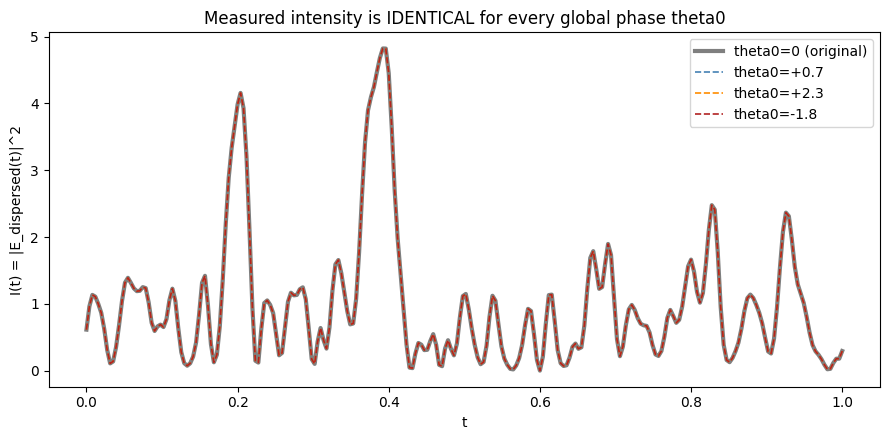

theta0=+0.7: max relative intensity difference = 1.29e-15
theta0=+2.3: max relative intensity difference = 7.37e-16
theta0=-1.8: max relative intensity difference = 7.37e-16


In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))
I_original = np.abs(disperse(E_true, D1))**2
ax.plot(t, I_original, color='black', lw=3, alpha=0.5, label='theta0=0 (original)')

max_diffs = []
for theta0, color in [(0.7, 'steelblue'), (2.3, 'darkorange'), (-1.8, 'firebrick')]:
    E_shifted = E_true * np.exp(1j*theta0)
    I_shifted = np.abs(disperse(E_shifted, D1))**2
    ax.plot(t, I_shifted, color=color, lw=1.2, ls='--', label=f'theta0={theta0:+.1f}')
    max_diffs.append(global_phase_invariance_check(E_true, D1, theta0))

ax.set_xlabel('t'); ax.set_ylabel('I(t) = |E_dispersed(t)|^2')
ax.set_title('Measured intensity is IDENTICAL for every global phase theta0')
ax.legend()
plt.tight_layout()
plt.savefig('phase_vs_phase_difference_invariance.png', dpi=90)
plt.show()

for theta0, diff in zip([0.7, 2.3, -1.8], max_diffs):
    print(f'theta0={theta0:+.1f}: max relative intensity difference = {diff:.2e}')


## §3 Relative Phase Cancels theta0; Absolute Phase Doesn't

Plot $\phi(t)$ and $\phi(t)+\theta_0$ side by side with their relative
phase $\phi(t)-\phi(t_{ref})$. The absolute curves are offset from each
other by a visible constant; the relative-phase curves land exactly on top
of each other -- $\theta_0$ never shows up in a difference.

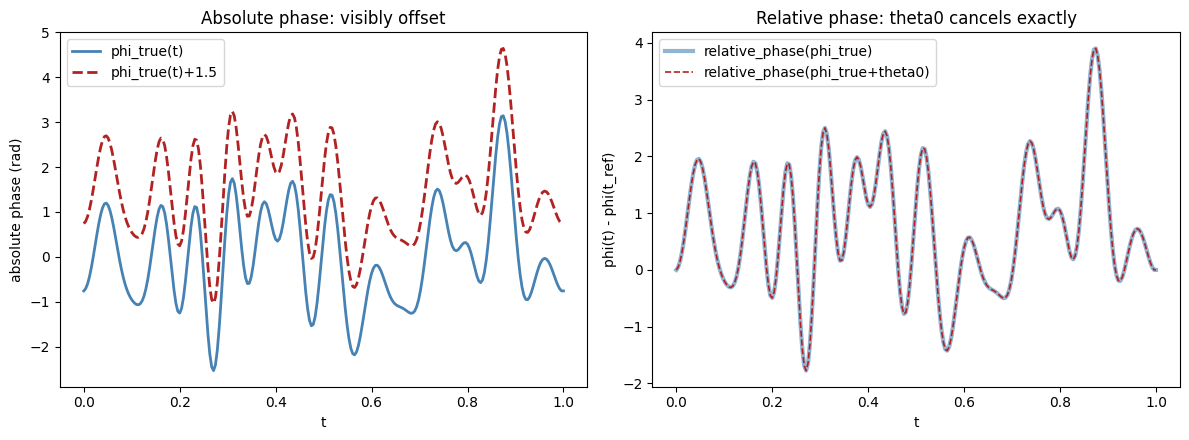

max |relative_phase(phi_true) - relative_phase(phi_true+theta0)| = 4.44e-16


In [3]:
theta0 = 1.5
phi_shifted = phi_true + theta0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(t, phi_true, color='steelblue', lw=2, label='phi_true(t)')
axes[0].plot(t, phi_shifted, color='firebrick', lw=2, ls='--', label=f'phi_true(t)+{theta0}')
axes[0].set_xlabel('t'); axes[0].set_ylabel('absolute phase (rad)')
axes[0].set_title('Absolute phase: visibly offset')
axes[0].legend()

rel_true = relative_phase(phi_true)
rel_shifted = relative_phase(phi_shifted)
axes[1].plot(t, rel_true, color='steelblue', lw=3, alpha=0.6, label='relative_phase(phi_true)')
axes[1].plot(t, rel_shifted, color='firebrick', lw=1.2, ls='--', label='relative_phase(phi_true+theta0)')
axes[1].set_xlabel('t'); axes[1].set_ylabel('phi(t) - phi(t_ref)')
axes[1].set_title('Relative phase: theta0 cancels exactly')
axes[1].legend()
plt.tight_layout()
plt.savefig('phase_vs_phase_difference_relative.png', dpi=90)
plt.show()

print(f'max |relative_phase(phi_true) - relative_phase(phi_true+theta0)| = '
      f'{np.max(np.abs(rel_true - rel_shifted)):.2e}')


## §4 Run Real GS: Raw Output Has a Global Offset, Corrected Doesn't

Generate real measurements $I_1, I_2$ from $E_{true}$, run
`gs_core.retrieve_phase`, and compare its output to the truth two ways: the
raw retrieved phase (which can carry an arbitrary offset), and the same
phase after fitting and removing that one constant.

  fitted_global_offset_rad: 0.0240
  raw_absolute_phase_rmse: 0.0240
  offset_corrected_phase_rmse: 0.0001
  relative_phase_rmse: 0.0001


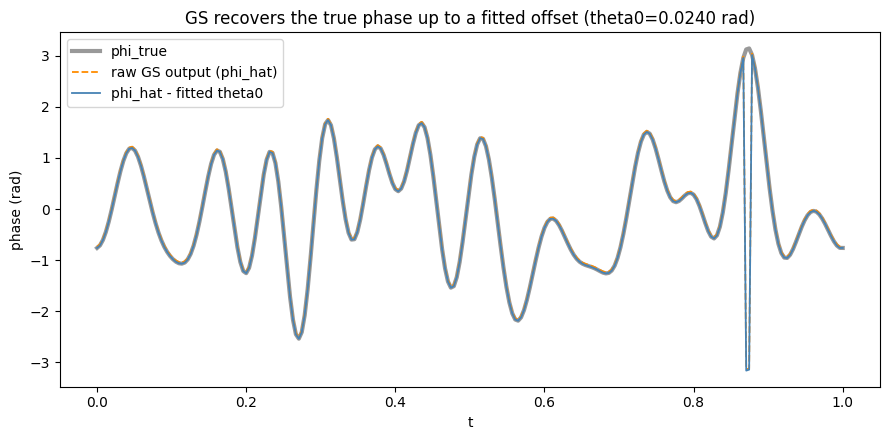

In [4]:
result = verify_phase_difference_recovery(E_true, D1, D2, n_iter=50)
for k, v in result.items():
    print(f'  {k}: {v:.4f}')

I1 = np.abs(disperse(E_true, D1))**2
I2 = np.abs(disperse(E_true, D2))**2
phi_hat, errors = retrieve_phase(I1, I2, D1, D2, n_iter=50)
theta0_fit = best_fit_global_offset(phi_true, phi_hat)
phi_hat_corrected = phi_hat - theta0_fit

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t, phi_true, color='black', lw=3, alpha=0.4, label='phi_true')
ax.plot(t, phi_hat, color='darkorange', lw=1.3, ls='--', label='raw GS output (phi_hat)')
ax.plot(t, phi_hat_corrected, color='steelblue', lw=1.3, label='phi_hat - fitted theta0')
ax.set_xlabel('t'); ax.set_ylabel('phase (rad)')
ax.set_title(f'GS recovers the true phase up to a fitted offset (theta0={theta0_fit:.4f} rad)')
ax.legend()
plt.tight_layout()
plt.savefig('phase_vs_phase_difference_gs_recovery.png', dpi=90)
plt.show()


## §5 The Sharp Version: GS's Output Is Bit-Identical

The strongest form of the claim: since $I_1, I_2$ are *provably* identical
whether or not $\theta_0$ was injected into the input (§2), GS's *output*
must be bit-identical too -- not just numerically close. Run GS twice, once
on $E_{true}$ and once on $E_{true}\cdot e^{i\theta_0}$, and diff the two
retrieved phase arrays directly.

In [5]:
max_diff = gs_output_invariant_to_input_global_phase(E_true, D1, D2, theta0=2.0, n_iter=50)
print(f'max |phi_hat(E) - phi_hat(E * exp(i*2.0))| = {max_diff:.2e}')
print('(not just small -- structurally invisible to the entire pipeline)')


max |phi_hat(E) - phi_hat(E * exp(i*2.0))| = 1.78e-15
(not just small -- structurally invisible to the entire pipeline)


## Summary

| Quantity | Recoverable from I1, I2? |
|---|---|
| Absolute phase $\phi(t)$ | **No** -- any global $\theta_0$ is invisible to intensity |
| Phase difference $\phi(t_1)-\phi(t_2)$ | **Yes** -- $\theta_0$ cancels exactly |
| GS's raw output | Matches truth up to one unknown constant |
| GS's output given a global-phase-shifted input | **Bit-identical** to the unshifted case |

This is exactly what `retrieve_phase`'s docstring already says --
"recovered phase phi(t) in radians (up to global phase offset)" -- worked
through explicitly rather than taken on faith.